# Latih Model Deteksi Rokok, Vape & Asap (YOLO11n)

Hasil akhir notebook ini adalah file **`smoking_vape.pt`** dengan 3 kelas:
- `rokok`: batang rokok
- `vape`: perangkat vape / pod / rokok elektrik
- `asap`: kepulan asap/uap yang diembuskan (*ngepul*). Tetap terdeteksi walau rokok/vape disembunyikan.

File itu dipakai oleh `smoking_detector.py`.

> **Data asap publik masih sedikit.** Untuk hasil terbaik, rekam sendiri orang yang sedang
> mengepulkan asap/vape di lokasi kamera, beri label `asap` di Roboflow (gratis), lalu tambahkan
> project-nya ke `DATASETS` di langkah 3. Jangan memakai dataset **asap kebakaran**, karena bentuknya berbeda.

**Langkah:**
1. Menu **Runtime → Change runtime type → T4 GPU → Save**.
2. Buat akun gratis di [roboflow.com](https://roboflow.com), lalu ambil API key di
   **Settings → API Keys** (Private API Key).
3. Menu **Runtime → Run all**. Saat diminta, tempel API key Roboflow.
4. Tunggu sampai selesai (±1–2 jam untuk 80 epoch). Jangan tutup tab browser.
5. File `smoking_vape.pt` otomatis terunduh. Taruh di folder `Yolo` (sebelah `smoking_detector.py`).

Dataset bawaan (publik, Roboflow Universe):
- [takoyati/cigarette-vape-detection](https://universe.roboflow.com/takoyati/cigarette-vape-detection)
- [livestreamdetection/smoking-vape-detection](https://universe.roboflow.com/livestreamdetection/smoking-vape-detection)

Periksa lisensi tiap dataset di halamannya sebelum dipakai di luar keperluan belajar.

## 1. Cek GPU

In [1]:
!nvidia-smi

Fri Oct  2 07:10:13 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Install library

In [2]:
%pip install -q ultralytics roboflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 63.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 333.6/333.6 kB 28.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 106.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.2/95.2 kB 7.5 MB/s eta 0:00:00


## 3. Pengaturan

Ubah `DATASETS` bila ingin menambah dataset lain dari Roboflow Universe
(ambil `workspace` dan `project` dari URL: `universe.roboflow.com/<workspace>/<project>`).

Nama kelas di tiap dataset berbeda-beda, jadi kelas dipetakan otomatis dengan kata kunci.
Hasil pemetaan dicetak di langkah 5. Periksa, dan ubah kata kunci bila ada yang salah.

In [3]:
# (workspace, project, versi). Versi None = versi terbaru.
# (workspace, project, versi). Versi None = versi terbaru.
# Semua dataset di bawah sudah diperiksa secara visual (isi label sesuai kelas tujuan).
DATASETS = [
    ("takoyati", "cigarette-vape-detection", 10),               # 5.774 foto: rokok & vape (CC BY 4.0)
    ("livestreamdetection", "smoking-vape-detection", 3),       # ±340 foto: kepulan asap & vape (CC BY 4.0)
    ("tiara-fb7pp", "vaping-ulrul", 7),                         # 2.000 foto: kepulan uap vape & vape pod (CC BY 4.0)
    ("spd", "smoking-person-detection-h0a2x", 13),              # 2.789 foto: asap rokok tipis, rokok, vape (Public Domain)
    ("project-i6bzi", "smoking-person-detection-ec7ec", 1),     # 2.349 foto: rokok di mulut/tangan (CC BY 4.0)
    # ("workspace-anda", "rekaman-asap-sendiri", None),         # tambahkan data asap rekaman sendiri
]

NAMES = ["rokok", "vape", "asap"]

# Pemetaan khusus per project, bila nama label di dataset menyesatkan (diperiksa secara visual):
# - smoking-vape-detection: 'smoking' = KEPULAN ASAP, 'vaping' = PERANGKAT VAPE
# - smoking-person-detection-ec7ec: 'smoke' = BATANG ROKOK (bukan asap)
CLASS_OVERRIDES = {
    "smoking-vape-detection": {"smoking": "asap", "vaping": "vape"},
    "smoking-person-detection-ec7ec": {"smoke": "rokok"},
}

# Urutan pengecekan: DIBUANG -> asap -> vape -> rokok (huruf kecil, cocok sebagian).
# 'smoking'/'vaping' adalah kotak AKSI (seluruh orang), bukan objek, jadi dibuang.
IGNORE_KEYWORDS = ["smoking", "vaping", "person", "face", "hand", "mouth", "fire", "flame"]
ASAP_KEYWORDS = ["smoke", "asap", "cloud", "vapor", "vapour", "exhale"]
VAPE_KEYWORDS = ["vape", "e-cig", "ecig", "e_cig", "pod", "elektrik"]
CIGARETTE_KEYWORDS = ["cigar", "cig", "rokok", "kretek"]

# Contoh negatif (opsional): .zip berisi foto benda yang sering dikira rokok/vape/asap
# (kotak earbuds, HP, pulpen, korek, uap kopi panas...). Bisa diambil dengan tombol
# "Capture foto" di panel. Diunggah di langkah 6, lalu dipakai sebagai data "bukan apa-apa".
USE_NEGATIVE_ZIP = True

EPOCHS = 60        # ±13.000 foto: ±2 jam di T4. Kurangi (mis. 40) bila waktu Colab terbatas
IMGSZ = 640

## 4. Unduh dataset dari Roboflow

In [4]:
from getpass import getpass
from roboflow import Roboflow

ROBOFLOW_API_KEY = getpass("Tempel API key Roboflow lalu tekan Enter: ")
rf = Roboflow(api_key=ROBOFLOW_API_KEY)

downloaded = []
for workspace, project_name, version in DATASETS:
    try:
        project = rf.workspace(workspace).project(project_name)
    except Exception as e:
        print(f"X {workspace}/{project_name}: tidak bisa dibuka ({e})")
        continue
    if version is not None:
        numbers = [version]
    else:
        try:
            numbers = sorted({int(str(v.version).split("/")[-1]) for v in project.versions()}, reverse=True)
        except Exception:
            numbers = list(range(30, 0, -1))
    for number in numbers:
        try:
            ds = project.version(number).download("yolov8", location=f"/content/datasets/{project_name}")
        except Exception:
            continue
        print(f"OK {workspace}/{project_name} versi {number} -> {ds.location}")
        downloaded.append(ds.location)
        break
    else:
        print(f"X {workspace}/{project_name}: tidak ada versi yang bisa diunduh")

assert downloaded, "Tidak ada dataset yang berhasil diunduh. Cek API key dan nama dataset."

Tempel API key Roboflow lalu tekan Enter: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/datasets/cigarette-vape-detection in yolov8:: 100%|██████████| 11560/11560 [00:01<00:00, 8624.26it/s]


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
OK takoyati/cigarette-vape-detection versi 10 -> /content/datasets/cigarette-vape-detection
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/datasets/smoking-vape-detection in yolov8:: 100%|██████████| 690/690 [00:00<00:00, 10817.58it/s]

OK livestreamdetection/smoking-vape-detection versi 3 -> /content/datasets/smoking-vape-detection
loading Roboflow workspace...


...


Extracting Dataset Version Zip to /content/datasets/smoking-person-detection-h0a2x in yolov8:: 100%|██████████| 5590/5590 [00:00<00:00, 10227.77it/s]

OK spd/smoking-person-detection-h0a2x versi 13 -> /content/datasets/smoking-person-detection-h0a2x
loading Roboflow workspace...


loading Roboflow project...



Extracting Dataset Version Zip to /content/datasets/smoking-person-detection-ec7ec in yolov8:: 100%|██████████| 4710/4710 [00:00<00:00, 8364.13it/s]

OK project-i6bzi/smoking-person-detection-ec7ec versi 1 -> /content/datasets/smoking-person-detection-ec7ec


## 5. Gabungkan dataset & petakan kelas → `rokok`, `vape`, `asap`

Gambar yang hanya berisi kelas yang dibuang (mis. `smoking`) tidak dipakai, supaya rokok
yang terlihat di gambar itu tidak dipelajari sebagai "bukan rokok".

In [5]:
import random
import shutil
from collections import Counter
from pathlib import Path

import yaml

OUT = Path("/content/merged")
shutil.rmtree(OUT, ignore_errors=True)


def map_class(name, project=""):
    override = CLASS_OVERRIDES.get(project, {})
    if name in override:
        return NAMES.index(override[name])
    n = name.lower()
    if any(k in n for k in IGNORE_KEYWORDS):
        return None
    if any(k in n for k in ASAP_KEYWORDS):
        return 2
    if any(k in n for k in VAPE_KEYWORDS):
        return 1
    if any(k in n for k in CIGARETTE_KEYWORDS):
        return 0
    return None


def to_box(values):
    # Label segmentasi (poligon) diubah menjadi kotak
    if len(values) > 4:
        xs, ys = values[0::2], values[1::2]
        x1, x2, y1, y2 = min(xs), max(xs), min(ys), max(ys)
        return [(x1 + x2) / 2, (y1 + y2) / 2, x2 - x1, y2 - y1]
    return values[:4]


boxes, images, skipped = Counter(), Counter(), 0
for root in map(Path, downloaded):
    names = yaml.safe_load(open(root / "data.yaml"))["names"]
    if isinstance(names, dict):
        names = [names[k] for k in sorted(names)]
    mapping = {i: map_class(n, root.name) for i, n in enumerate(names)}
    print(f"\n{root.name}:")
    for i, n in enumerate(names):
        print(f"   {n!r:30} -> {NAMES[mapping[i]] if mapping[i] is not None else 'DIBUANG'}")

    for src, dst in (("train", "train"), ("valid", "val"), ("test", "test")):
        img_dir = root / src / "images"
        if not img_dir.exists():
            continue
        (OUT / dst / "images").mkdir(parents=True, exist_ok=True)
        (OUT / dst / "labels").mkdir(parents=True, exist_ok=True)
        for img in img_dir.iterdir():
            label_file = root / src / "labels" / (img.stem + ".txt")
            raw = label_file.read_text().split("\n") if label_file.exists() else []
            raw = [line.split() for line in raw if len(line.split()) >= 5]
            lines = []
            for parts in raw:
                cls = mapping.get(int(parts[0]))
                if cls is None:
                    continue
                box = to_box([float(v) for v in parts[1:]])
                lines.append(f"{cls} " + " ".join(f"{v:.6f}" for v in box))
                boxes[(dst, NAMES[cls])] += 1
            if raw and not lines:
                skipped += 1
                continue
            new_name = f"{root.name}_{img.name}"
            shutil.copy(img, OUT / dst / "images" / new_name)
            (OUT / dst / "labels" / (Path(new_name).stem + ".txt")).write_text("\n".join(lines))
            images[dst] += 1

# Bila tidak ada data validasi, ambil 10% dari train
if images["val"] == 0:
    (OUT / "val" / "images").mkdir(parents=True, exist_ok=True)
    (OUT / "val" / "labels").mkdir(parents=True, exist_ok=True)
    train_imgs = sorted((OUT / "train" / "images").iterdir())
    for img in random.Random(0).sample(train_imgs, max(1, len(train_imgs) // 10)):
        shutil.move(img, OUT / "val" / "images" / img.name)
        lbl = OUT / "train" / "labels" / (img.stem + ".txt")
        shutil.move(lbl, OUT / "val" / "labels" / lbl.name)
        images["train"] -= 1
        images["val"] += 1

data = {"path": str(OUT), "train": "train/images", "val": "val/images", "names": NAMES}
if images["test"]:
    data["test"] = "test/images"
yaml.safe_dump(data, open(OUT / "data.yaml", "w"), allow_unicode=True)

print("\nGambar per bagian:", dict(images), f"| dilewati: {skipped}")
print("Kotak per kelas:", {f"{s}/{c}": n for (s, c), n in sorted(boxes.items())})
assert boxes, "Tidak ada label rokok/vape/asap. Periksa pemetaan kelas di atas."
for name in NAMES:
    total = sum(n for (s, c), n in boxes.items() if c == name and s == "train")
    if total < 200:
        print(f"PERHATIAN: kelas '{name}' hanya {total} kotak di data latih. "
              f"Deteksi '{name}' akan lemah; tambah data sendiri (lihat langkah 3).")


cigarette-vape-detection:
   'cigarette'                    -> rokok
   'vape'                         -> vape

smoking-vape-detection:
   'smoking'                      -> asap
   'vaping'                       -> vape

vaping-ulrul:
   'asap'                         -> asap
   'vape-pod'                     -> vape

smoking-person-detection-h0a2x:
   'cigarette'                    -> rokok
   'person'                       -> DIBUANG
   'smoke'                        -> asap

smoking-person-detection-ec7ec:
   'person'                       -> DIBUANG
   'smoke'                        -> rokok

Gambar per bagian: {'train': 10088, 'val': 2137, 'test': 837} | dilewati: 173
Kotak per kelas: {'test/asap': 40, 'test/rokok': 550, 'test/vape': 429, 'train/asap': 1756, 'train/rokok': 6554, 'train/vape': 3859, 'val/asap': 293, 'val/rokok': 1198, 'val/vape': 960}


## 6. Contoh negatif (opsional)

Unggah **.zip** berisi foto benda yang sering salah dikira rokok/vape/asap: kotak earbuds, HP,
pulpen, korek, gelas kopi beruap, dan latar tempat kamera dipasang. Foto bisa diambil dengan
tombol **Capture foto** di panel (folder `captures/`). Usahakan 30–100 foto dari berbagai sudut.

Foto ini dipakai **tanpa label**, sehingga model belajar bahwa benda itu *bukan* rokok/vape/asap.
Tekan **Cancel** bila tidak punya.

In [6]:
import io
import zipfile

added = 0
if USE_NEGATIVE_ZIP:
    from google.colab import files
    try:
        uploaded = files.upload()
    except Exception:
        uploaded = {}
    for zip_name, content in uploaded.items():
        if not zip_name.lower().endswith(".zip"):
            print(f"Dilewati (bukan .zip): {zip_name}")
            continue
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            for member in z.namelist():
                if member.startswith("__MACOSX") or not member.lower().endswith((".jpg", ".jpeg", ".png")):
                    continue
                target = f"negatif_{added:04d}{Path(member).suffix.lower()}"
                (OUT / "train" / "images" / target).write_bytes(z.read(member))
                (OUT / "train" / "labels" / (Path(target).stem + ".txt")).write_text("")
                added += 1
print(f"{added} foto contoh negatif ditambahkan ke data latih")

0 foto contoh negatif ditambahkan ke data latih


## 7. Latih model

In [7]:
from ultralytics import YOLO

model = YOLO("yolo11n.pt")
model.train(
    data=str(OUT / "data.yaml"),
    epochs=EPOCHS,
    imgsz=IMGSZ,
    patience=20,          # berhenti lebih awal bila tidak membaik 20 epoch
    batch=16,
    project="/content/runs",
    name="rokok_vape",
    exist_ok=True,
)

Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/merged/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=60, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=rokok_vape, nbs=64, nms=None, opset=None, optimize=False, optimiz

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x7d672a933d20>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04

## 8. Hasil & akurasi

- **mAP50** mendekati 1.0 = sangat baik. Di atas 0.6 sudah layak dicoba; di bawah 0.4 perlu data lebih banyak.
- Lihat nilai **per kelas**: bila `asap` jauh lebih rendah dari `rokok`/`vape`, tambah data asap sendiri.
- Confusion matrix menunjukkan seberapa sering kelas tertukar satu sama lain atau dengan latar belakang.

Ultralytics 8.4.171 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 100 layers, 2,582,737 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1782.3±926.0 MB/s, size: 47.4 KB)
val: Scanning /content/merged/val/labels.cache... 2137 images, 4 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 2137/2137 689.5Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 134/134 6.1it/s 21.8s
                   all       2137       2451      0.703      0.644      0.647      0.394
                 rokok       1154       1198      0.689      0.695      0.637      0.323
                  vape        780        960      0.817      0.804      0.853      0.631
                  asap        241        293      0.602      0.433      0.452      0.227
Speed: 1.1ms preprocess, 4.5ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to /content/runs/detect/val

mAP50

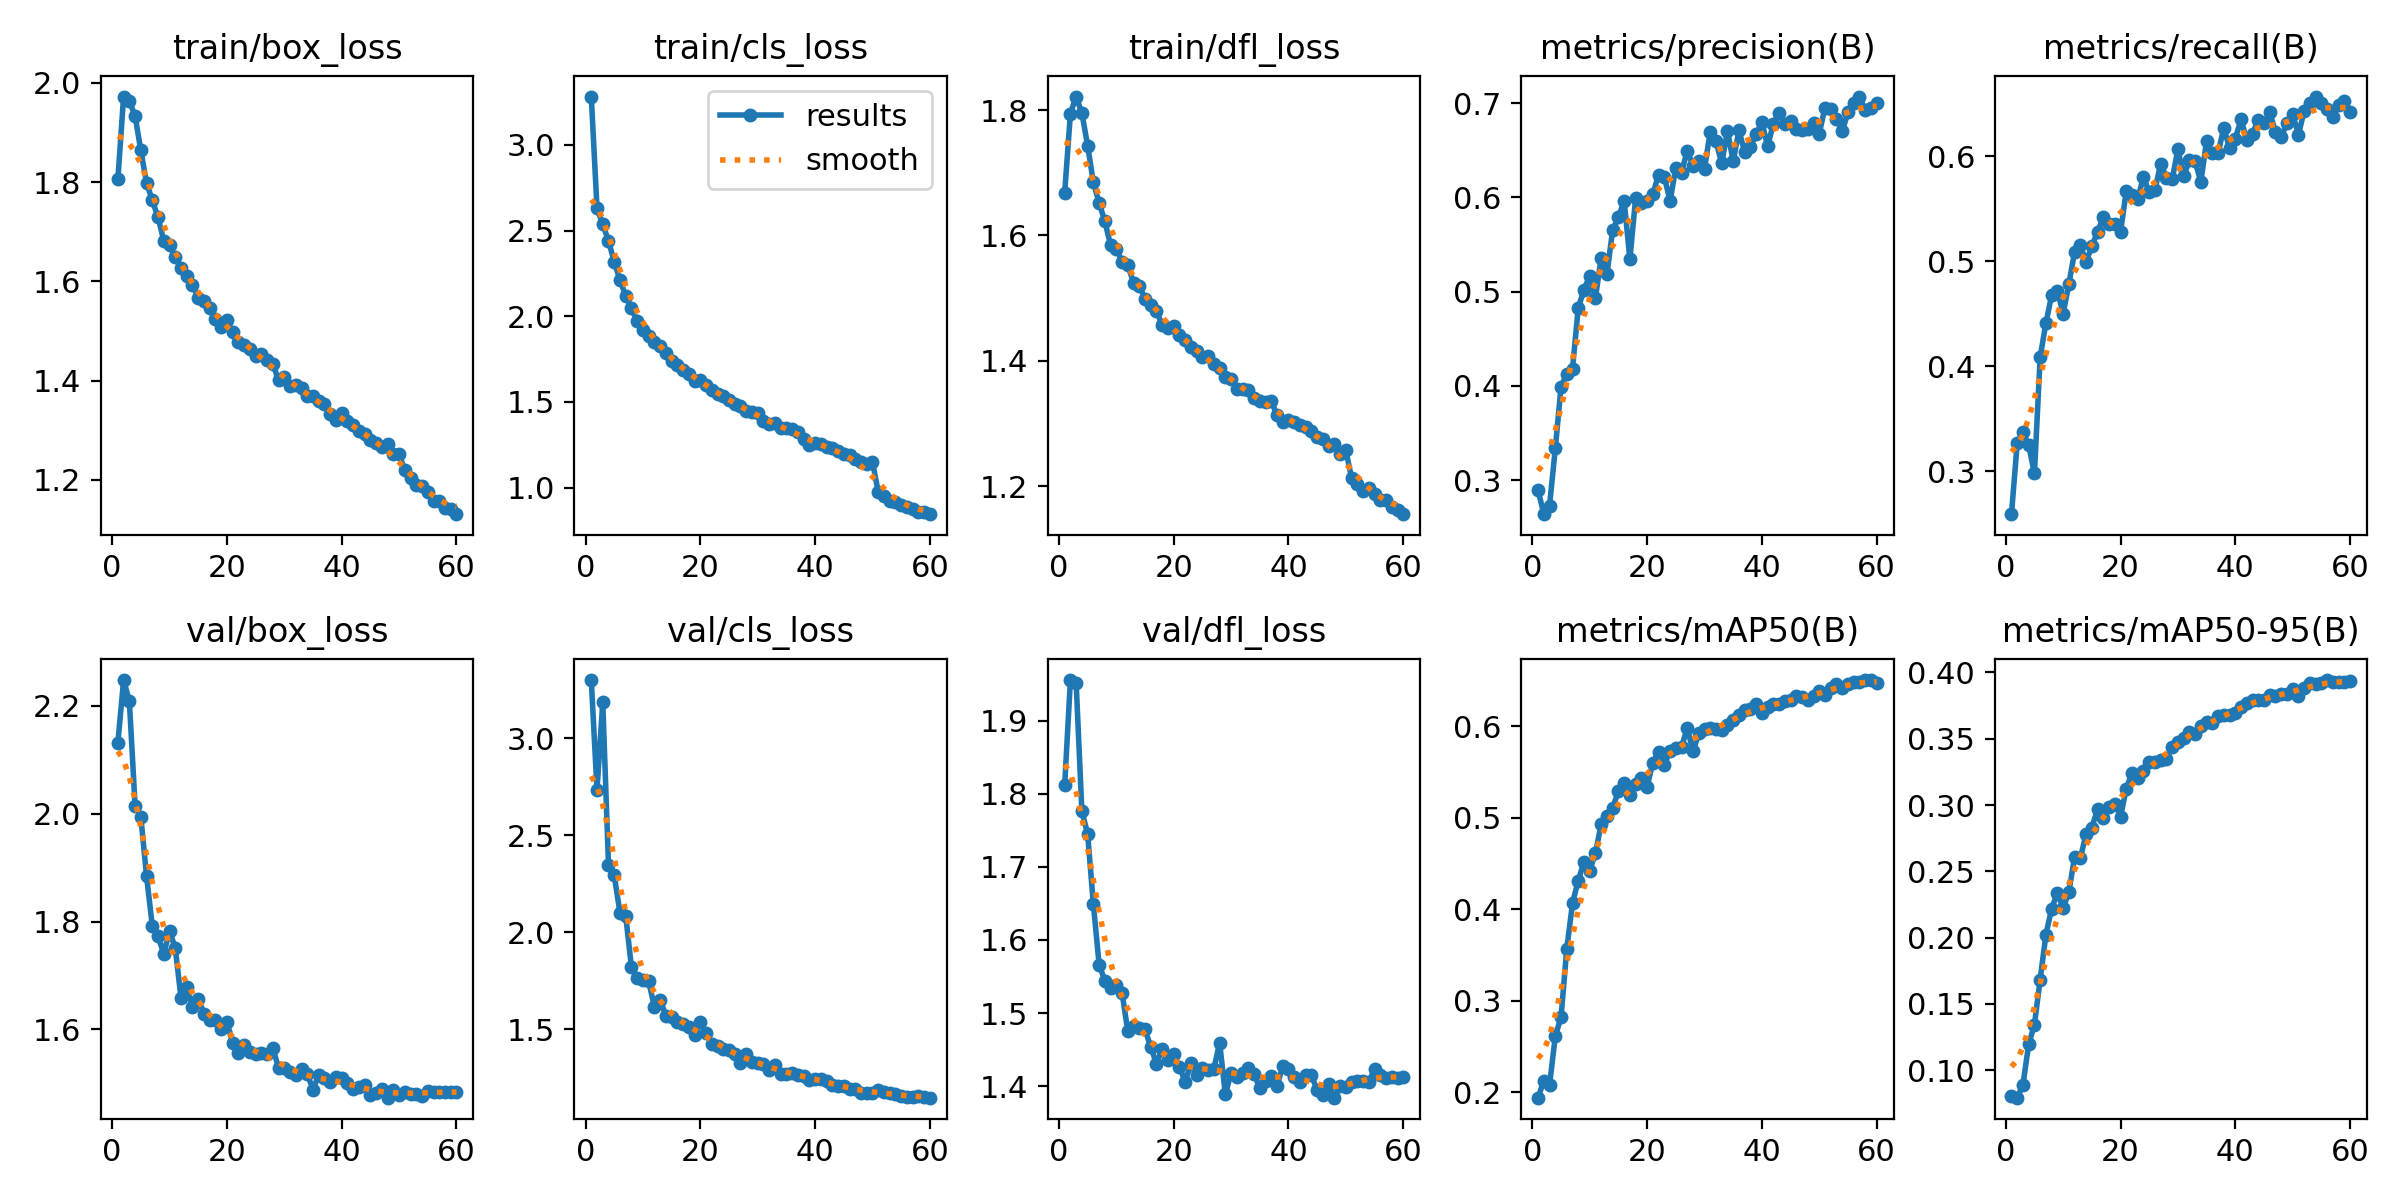

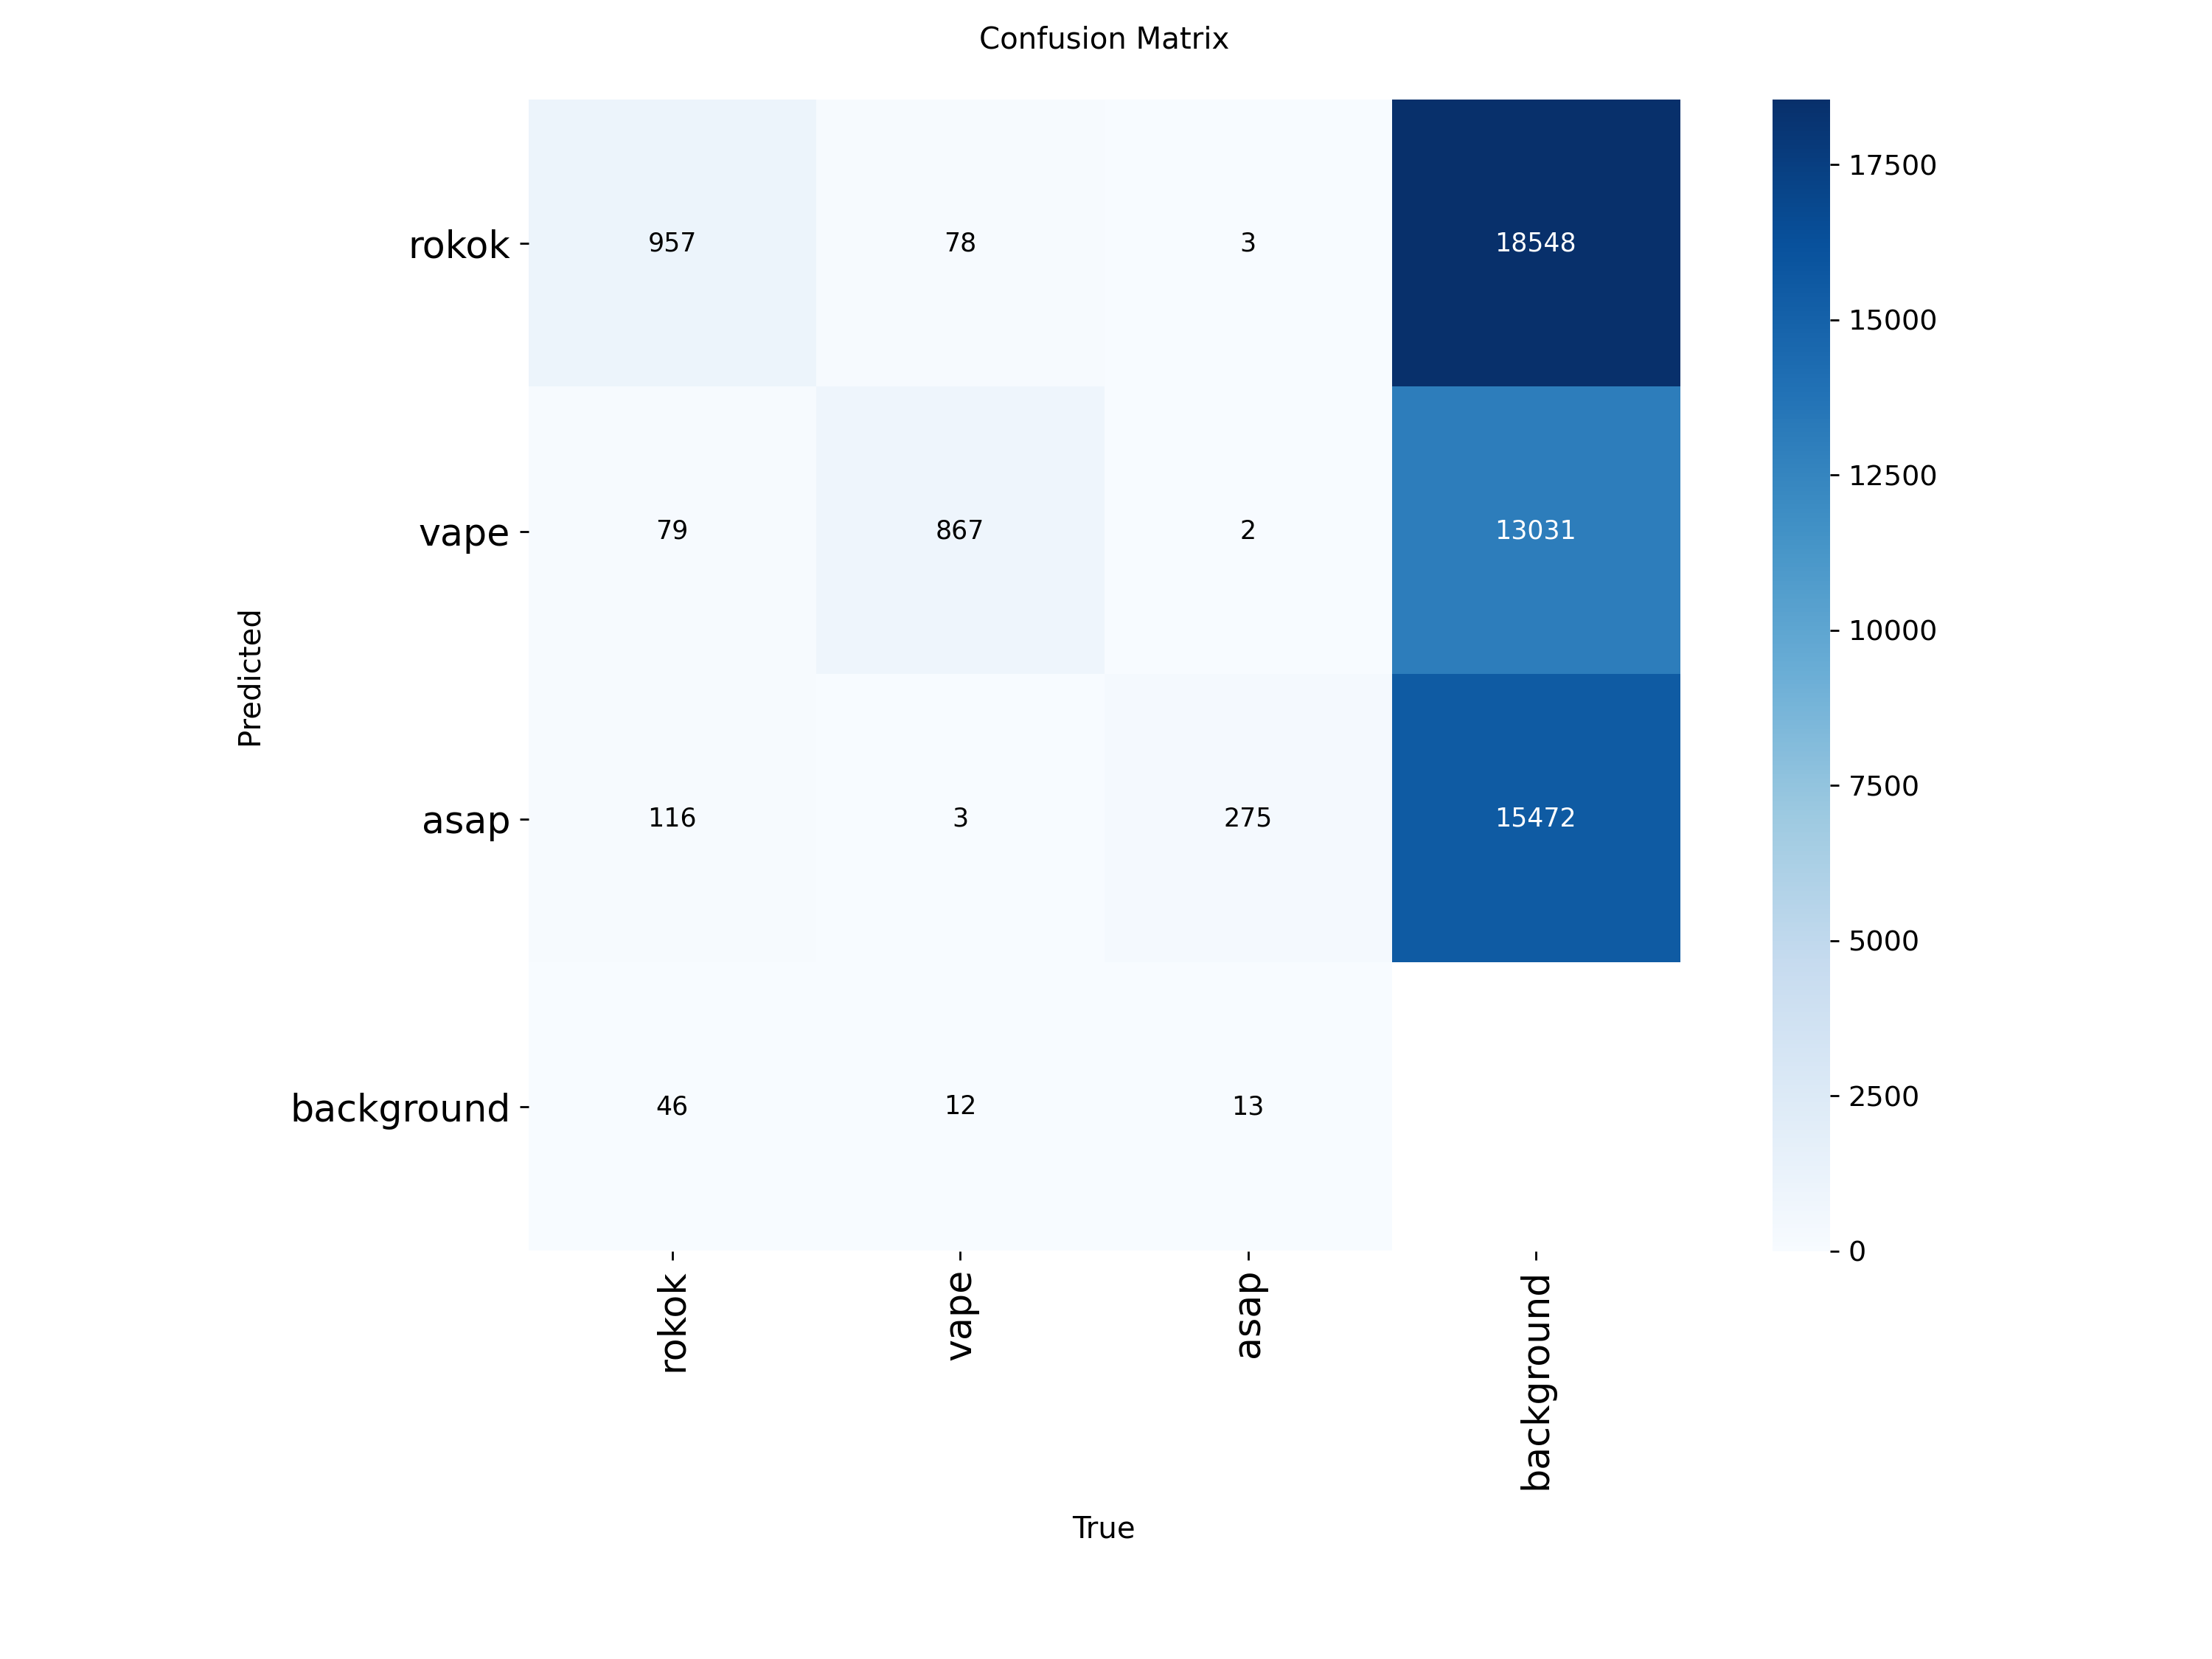

In [8]:
from IPython.display import Image, display

BEST = "/content/runs/rokok_vape/weights/best.pt"
best = YOLO(BEST)
metrics = best.val(data=str(OUT / "data.yaml"), split="val")
print(f"\nmAP50     : {metrics.box.map50:.3f}")
print(f"mAP50-95  : {metrics.box.map:.3f}")
for i, name in enumerate(NAMES):
    print(f"  {name:6} mAP50-95: {metrics.box.maps[i]:.3f}")

display(Image("/content/runs/rokok_vape/results.png", width=900))
display(Image("/content/runs/rokok_vape/confusion_matrix.png", width=600))

## 9. Contoh prediksi

In [ ]:
val_images = sorted((OUT / "val" / "images").iterdir())
sample = random.Random(1).sample(val_images, min(6, len(val_images)))
best.predict(sample, conf=0.35, save=True, project="/content/runs", name="contoh", exist_ok=True, verbose=False)
for f in sorted(Path("/content/runs/contoh").iterdir())[:6]:
    display(Image(str(f), width=420))

## 10. Unduh model

File `smoking_vape.pt` akan terunduh. Taruh di folder `Yolo`, lalu di Panel pilih
mode **Deteksi rokok & vape**.

Bila unduhan tidak muncul, buka ikon folder di kiri, klik kanan `smoking_vape.pt` → Download.

In [10]:
shutil.copy(BEST, "/content/smoking_vape.pt")
from google.colab import files
files.download("/content/smoking_vape.pt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>